### Bibliotecas

In [136]:
import geemap
import numpy as np
import geopandas as gpd
import geobr
import ee
import json
import matplotlib.pyplot as plt
import os
import pandas as pd
from pathlib import Path

In [30]:
# Autenticação

ee.Authenticate()
ee.Initialize(project='ee-wanderamufv')

In [83]:
# Lendo o vetor do DF

DF = geobr.read_state(code_state='DF', year=2018)

DF

,code_state,name_state,abbrev_state,code_region,name_region,year,geometry
0,53.0,Distrito Federal,DF,5.0,Centro-Oeste,2018.0,"POLYGON ((-48.27781 -16.0496, -47.3085 -16.049..."


In [ ]:
# pontos_aleatorios = DF['geometry'].sample_points(size=50)
# print(pontos_aleatorios)

0    MULTIPOINT ((-47.83263 -15.68592), (-47.74392 ...
Name: sampled_points, dtype: geometry


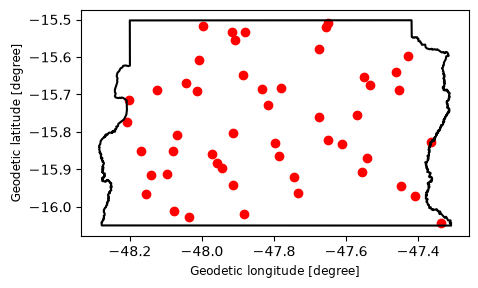

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))

DF.boundary.plot(ax=ax, color='k')
# pontos_aleatorios.plot(ax=ax, color='r')

plt.show()

In [86]:
# Covertendo as coordenadas de geodataframe para json

df_json = DF.to_json()

In [87]:
# Carregando o arquivo json
df_json_coords = json.loads(df_json)
type(df_json_coords)

dict

In [88]:
print(df_json_coords)

{'type': 'FeatureCollection', 'features': [{'id': '0', 'type': 'Feature', 'properties': {'code_state': 53.0, 'name_state': 'Distrito Federal', 'abbrev_state': 'DF', 'code_region': 5.0, 'name_region': 'Centro-Oeste', 'year': 2018.0}, 'geometry': {'type': 'Polygon', 'coordinates': [[[-48.277811199999995, -16.049597799999997], [-47.3085041, -16.049971399999997], [-47.30997489999999, -16.048485999999997], [-47.308494499999995, -16.04567429999999], [-47.31018299999999, -16.044519599999994], [-47.308500300000006, -16.042092], [-47.3126749, -16.0421107], [-47.31000619999999, -16.0362735], [-47.316932900000005, -16.036191599999995], [-47.32246879999999, -16.026514], [-47.32540609999999, -16.027100699999995], [-47.3256782, -16.029618699999997], [-47.337363599999996, -16.0174428], [-47.3406074, -16.01943619999999], [-47.341057, -16.018016199999995], [-47.33969449999999, -16.016873299999997], [-47.341162399999995, -16.0153387], [-47.33874129999999, -16.0150364], [-47.3384231, -16.013449800000007]

In [89]:
# Selecionando coordenadas
df_coord = df_json_coords['features']

In [90]:
# Convertendo as coordenadas para o tipo FeatureCollection do Earth Engine
aoi = ee.FeatureCollection(df_coord)

In [91]:
# Chamando a coleção
# '2001-07-20', '2001-07-21'

collection = ee.ImageCollection('LANDSAT/LE07/C02/T1_L2')\
    .filterDate('2001-07-20', '2001-07-21')\
    .filterBounds(aoi)\


print(f'Número de cenas: {collection.size().getInfo()}')

Número de cenas: 1


In [92]:
# Visualizando a cena utilizando o geemap

mapa = geemap.Map()
mapa.centerObject(aoi, zoom=7)
mapa.add_basemap('SATELLITE')
mapa.addLayer(collection.select('SR_B3', 'SR_B4', 'SR_B2'), {'gamma': 2}, 'RGB')
mapa.addLayerControl()

mapa

Map(center=[-15.781437324803912, -47.796830098960555], controls=(WidgetControl(options=['position', 'transpare…

In [93]:
# Converter de collection para image

img = ee.Image(collection.first())

In [94]:
# Calculando o NDVI

ndvi = img.normalizedDifference(['SR_B4', 'SR_B3'])

In [95]:
# Visualizando o NDVI

ndvi_vis = {
    'min': -0.035551728379874525,
    'max': 0.546458090641815,
    'palette': ['red', 'yellow', 'green']
    }
mapa.addLayer(ndvi, ndvi_vis, 'NDVI')

mapa

Map(bottom=18139.0, center=[-15.781437324803912, -47.796830098960555], controls=(WidgetControl(options=['posit…

In [96]:
for n, l in enumerate(mapa.layers):
    print(n + 1, l.name)

1 OpenStreetMap.Mapnik
2 Esri.WorldImagery
3 RGB
4 NDVI


### Série temporal de NDVI

In [189]:
collection2 = ee.ImageCollection('LANDSAT/LE07/C02/T1_L2')\
    .filterDate('2001-01-01', '2001-12-31')\
    .filterBounds(aoi)

print(f'Número de cenas: {collection2.size().getInfo()}')

Número de cenas: 34


In [190]:
# Função para NDVI

def calc_ndvi_collection(img):
    ndvi = img.normalizedDifference(['SR_B4', 'SR_B3']).rename('NDVI')
    return ndvi.copyProperties(img, ['system:time_start', 'system:index'])
    

In [191]:
# Gerando NDVI para coleção
NDVI2 = collection2.map(calc_ndvi_collection)

In [192]:
print(NDVI2.size().getInfo())                    # quantas imagens existem
print(NDVI2.first().propertyNames().getInfo())   # quais propriedades a 1ª imagem tem

34
['system:time_start', 'system:footprint', 'system:index', 'system:bands', 'system:band_names']


In [193]:
datas = NDVI2.aggregate_array('system:time_start').map(
    lambda t: ee.Date(t).format('YYYY-MM-dd')
).getInfo()

for i, d in enumerate(datas):
    print(i, d)

0 2001-01-18
1 2001-02-03
2 2001-02-19
3 2001-03-07
4 2001-03-23
5 2001-04-08
6 2001-04-24
7 2001-05-10
8 2001-05-26
9 2001-06-11
10 2001-07-13
11 2001-07-29
12 2001-08-14
13 2001-09-15
14 2001-12-04
15 2001-12-20
16 2001-01-09
17 2001-01-25
18 2001-02-10
19 2001-02-26
20 2001-03-30
21 2001-04-15
22 2001-05-01
23 2001-06-02
24 2001-06-18
25 2001-07-04
26 2001-07-20
27 2001-08-05
28 2001-08-21
29 2001-09-06
30 2001-09-22
31 2001-10-24
32 2001-11-09
33 2001-12-11


In [194]:
# Obtendo apenas um NDVI para conferência

ndvi_selecionado = NDVI2.filterDate('2001-12-10', '2001-12-12').first()

print(f'Cena: {ndvi_selecionado.getInfo()}')

Cena: {'type': 'Image', 'bands': [{'id': 'NDVI', 'data_type': {'type': 'PixelType', 'precision': 'float', 'min': -1, 'max': 1}, 'dimensions': [7791, 6941], 'crs': 'EPSG:32623', 'crs_transform': [30, 0, 65085, 0, -30, -1655385]}], 'properties': {'system:time_start': 1008075801546, 'system:footprint': {'type': 'LinearRing', 'coordinates': [[-47.288498637035104, -16.834315279140757], [-47.28690328268207, -16.831329377574935], [-47.19941056112929, -16.439801695344915], [-47.083502715763096, -15.91296932719627], [-46.96836499917092, -15.385979212026918], [-46.948480971598435, -15.293846441546684], [-46.931549785399085, -15.21359559532291], [-46.93016829338261, -15.203975496315785], [-47.26319423187314, -15.156508054211264], [-47.55200064585896, -15.114965710718145], [-48.63777762555597, -14.955445311016986], [-48.64189974517004, -14.96991972233206], [-48.64447591901035, -14.980529133027662], [-48.69784459114094, -15.21548809924951], [-48.80879148319319, -15.702532992783913], [-48.8984912823

In [195]:
# Gerando uma camada de pontos aleatórios
pontos = ee.FeatureCollection.randomPoints(region=geemap.gdf_to_ee(DF).geometry(), points=1000, seed=42)

In [196]:
pontos_gdf = geemap.ee_to_gdf(pontos)
type(pontos_gdf)
#pontos_gdf.to_file('gpkgs/pontos_gerados_ee.gpkg', driver='GPKG')

geopandas.geodataframe.GeoDataFrame

In [197]:
# Extrair valores de pixel com base em pontos
# pontos = geemap.gdf_to_ee(pontos_aleatorios)

# Convertendo o NDVI para bandas de ndvi
ndvi_bandas = NDVI2.toBands()

# Diretório de saída
work_dir = 'output'

# Definindo o arquivo de saída
saida_csv = os.path.join(work_dir, 'pts.csv')

# Extraindo valores
resultado_ee = geemap.extract_values_to_points(pontos, ndvi_bandas, scale=30)    # O resultado de extract_values_to_points é uma ee.FeatureCollection

In [198]:
type(resultado_ee)

ee.featurecollection.FeatureCollection

In [199]:
resultado_gdf = geemap.ee_to_gdf(resultado_ee)

# Removendo valores nulos
resultado_gdf = resultado_gdf.dropna(axis=1)


# Exportando como gpkg
resultado_gdf.to_file('gpkgs/pontos_extraidos.gpkg', layer='pontos', driver='GPKG')

resultado_gdf.head()

,geometry,LE07_221071_20010109_NDVI,LE07_221071_20010125_NDVI,LE07_221071_20010210_NDVI,LE07_221071_20010226_NDVI,LE07_221071_20010330_NDVI,LE07_221071_20010415_NDVI,LE07_221071_20010501_NDVI,LE07_221071_20010602_NDVI,LE07_221071_20010618_NDVI,LE07_221071_20010704_NDVI,LE07_221071_20010720_NDVI,LE07_221071_20010805_NDVI,LE07_221071_20010821_NDVI,LE07_221071_20010906_NDVI,LE07_221071_20010922_NDVI,LE07_221071_20011024_NDVI,LE07_221071_20011109_NDVI,LE07_221071_20011211_NDVI
0,POINT (-47.95893 -15.72442),0.267860,-0.382639,0.258533,0.257242,0.108969,-0.252904,0.246227,0.263062,0.204689,0.198599,0.189196,0.174829,0.174087,0.155329,0.129342,0.263434,0.185580,0.159175
1,POINT (-47.90392 -15.85153),0.170012,0.127638,0.173539,0.181404,0.159975,-0.335419,0.166224,0.132187,0.178017,0.147347,0.142704,0.141521,0.143971,0.133839,0.140283,0.201973,0.156483,0.202684
2,POINT (-47.60403 -15.65745),0.201413,0.171991,0.239772,0.207531,0.132738,-0.400695,0.206564,0.175280,0.167509,0.123723,0.139215,0.088900,0.120781,0.116576,0.127448,0.203352,0.160609,0.235542
3,POINT (-47.83429 -15.71673),0.080922,0.116669,0.180847,0.193069,0.167791,-0.385079,0.223071,0.190370,0.176673,0.152679,0.130844,0.100499,0.095190,0.115664,0.114798,0.158934,0.150296,0.203049
4,POINT (-47.85883 -16.04301),0.261543,0.196533,0.190048,0.214335,0.154180,0.085899,0.109141,0.060608,0.158333,0.145720,0.127410,0.107698,0.112783,0.093117,0.096673,0.162771,0.132455,0.255467


In [200]:
pasta = Path('C:/Users/letic/Documents/PDIPy_codes2/output')
pasta.mkdir(parents=True, exist_ok=True)   # cria a pasta se ela não existir

regiao = pontos.geometry().bounds()

geemap.ee_export_image(
    ndvi_selecionado.clip(regiao).toFloat(),
    filename=str(pasta / "ndvi_selecionado.tif"),
    scale=30,
    region=regiao,
    crs="EPSG:31983",
)

Generating URL ...
Please wait ...
Data downloaded to C:\Users\letic\Documents\PDIPy_codes2\output\ndvi_selecionado.tif
